# Reconnaissance de Variétés de Haricots Secs : Support Vector Machines (SVM)
**Mini-Projet 02**
*Pôle 2 : Modèles à Marges Maximales & Géométrie (SVM Linéaire & RBF)*

---
### Objectif du Notebook
Ce notebook implémente et évalue les classificateurs **Support Vector Machines (SVM)** pour la reconnaissance de 7 variétés de haricots secs à partir de 16 descripteurs morphologiques :
1. Exploration des données et diagnostic du déséquilibre de classes.
2. Découpage stratifié 80 % train / 20 % test (`random_state=42`).
3. Démonstration expérimentale et mathématique de l'impact critique du **Feature Scaling** sur les SVM.
4. Optimisation des hyperparamètres par **validation croisée stratifiée à 5 plis** sur le train ($C$ pour le SVM Linéaire, $C$ et $\gamma$ pour le SVM RBF).
5. Évaluation unique sur le jeu de test avec métriques complètes (**Macro F1-score**, Accuracy, Précision, Rappel).
6. Analyse de la **matrice de confusion $7 \times 7$** et interprétation morphologique des erreurs.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)


## 1. Chargement & Exploration des Données
Le jeu de données *Dry Bean Dataset* issu du dépôt officiel UCI contient 13 611 observations et 16 descripteurs morphologiques et géométriques. La variable cible `Class` comporte 7 variétés.


In [2]:
df = pd.read_csv('Dry_Bean_Dataset.csv')

X = df.drop(columns='Class')
y = df['Class']

print("Dimensions du dataset :", df.shape)
print("Nombre total de valeurs manquantes :", df.isna().sum().sum())
print("\nStatistiques descriptives des 16 variables :")
display(X.describe().T[['mean', 'std', 'min', '50%', 'max']])


Dimensions du dataset : (13611, 17)
Nombre total de valeurs manquantes : 0

Statistiques descriptives des 16 variables :


,mean,std,min,50%,max
Area,53048.284549,29324.095717,20420.000000,44652.000000,254616.000000
Perimeter,855.283459,214.289696,524.736000,794.941000,1985.370000
MajorAxisLength,320.141867,85.694186,183.601165,296.883367,738.860153
MinorAxisLength,202.270714,44.970091,122.512653,192.431733,460.198497
AspectRation,1.583242,0.246678,1.024868,1.551124,2.430306
Eccentricity,0.750895,0.092002,0.218951,0.764441,0.911423
ConvexArea,53768.200206,29774.915817,20684.000000,45178.000000,263261.000000
EquivDiameter,253.064220,59.177120,161.243764,238.438026,569.374358
Extent,0.749733,0.049086,0.555315,0.759859,0.866195
Solidity,0.987143,0.004660,0.919246,0.988283,0.994677


- Aucune valeur manquante n'est présente dans les 13 611 enregistrements.
- On observe une disparité d'échelles extrême : `Area` atteint des valeurs supérieures à 250 000 avec un écart-type de 29 324, tandis que des ratios comme `Compactness` ou `Solidity` oscillent entre 0 et 1. Cette hétérogénéité rendra la standardisation impérative pour les algorithmes sensibles aux distances euclidiennes comme les SVM.


### 1.1 Distribution des 7 Variétés


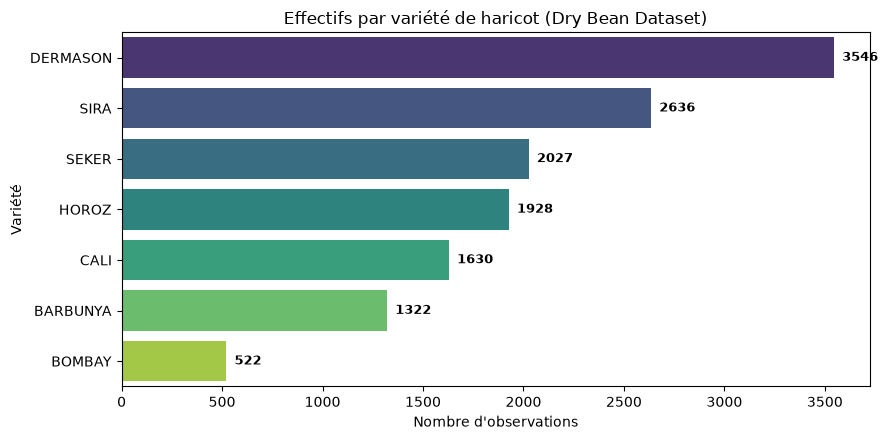

In [3]:
plt.figure(figsize=(9, 4.5))
order = y.value_counts().index
sns.countplot(data=df, y='Class', order=order, palette='viridis')
plt.title("Effectifs par variété de haricot (Dry Bean Dataset)")
plt.xlabel("Nombre d'observations")
plt.ylabel("Variété")
for index, value in enumerate(y.value_counts()[order]):
    plt.text(value + 40, index, str(value), va='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


- Le dataset présente un déséquilibre marqué : la classe majoritaire (*Dermason* : 3 546) est près de 7 fois plus nombreuse que la classe minoritaire (*Bombay* : 522).
- Ce déséquilibre confirme la nécessité d'utiliser le **Macro F1-score** comme métrique d'évaluation directrice afin d'accorder le même poids à toutes les variétés lors de l'optimisation.


### 1.2 Inspection Morphologique par Variété


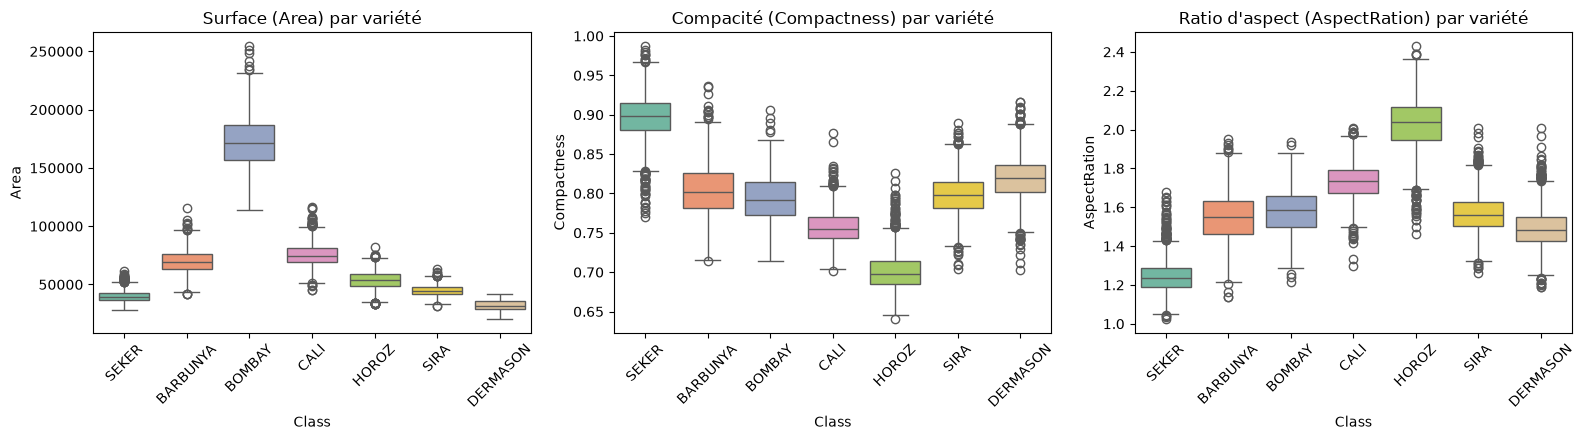

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(data=df, x='Class', y='Area', ax=axes[0], palette='Set2')
axes[0].set_title("Surface (Area) par variété")
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='Class', y='Compactness', ax=axes[1], palette='Set2')
axes[1].set_title("Compacité (Compactness) par variété")
axes[1].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='Class', y='AspectRation', ax=axes[2], palette='Set2')
axes[2].set_title("Ratio d'aspect (AspectRation) par variété")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


- **Séparabilité facile de Bombay :** Sa surface est sans égale dans le dataset, ce qui permettra une classification quasi-certaine.
- **Forme allongée de Horoz :** Son ratio d'aspect est nettement plus élevé que les autres, ce qui aide à l'isoler géométriquement.
- **Forte imbrication Dermason / Sira :** Leurs boîtes à moustaches se chevauchent presque entièrement sur la compacité et le ratio d'aspect, expliquant pourquoi ces deux variétés seront les plus difficiles à discriminer.


## 2. Découpage Stratifié 80 % Apprentissage / 20 % Test
Conformément au protocole partagé de l'équipe, nous isolons 20 % des données avec graine aléatoire fixée (`SEED = 42`) et stratification sur `Class`.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Jeu d'entraînement : {X_train.shape[0]} observations")
print(f"Jeu de test         : {X_test.shape[0]} observations")
print("\nVérification de la stratification (% dans train vs test) :")
display(pd.DataFrame({
    'Train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Test (%)': (y_test.value_counts(normalize=True) * 100).round(2)
}))


Jeu d'entraînement : 10888 observations
Jeu de test         : 2723 observations

Vérification de la stratification (% dans train vs test) :


,Train (%),Test (%)
Class,,
DERMASON,26.06,26.04
SIRA,19.37,19.35
SEKER,14.89,14.91
HOROZ,14.16,14.18
CALI,11.98,11.97
BARBUNYA,9.71,9.73
BOMBAY,3.84,3.82


- Les proportions relatives de chaque variété dans le jeu de test sont identiques à celles du jeu d'entraînement à 0.01 % près.
- Le jeu de test (2 723 graines) est strictement mis de côté et ne sera évalué qu'une seule fois à l'étape finale.


## 3. Démonstration de l'Impact de la Standardisation
Les SVM résolvent un problème d'optimisation quadratique reposant sur le calcul de distances euclidiennes et de produits scalaires $\langle x_i, x_j \rangle$.
Comparons un SVM RBF entraîné sur données brutes versus encapsulé dans un `Pipeline([('scaler', StandardScaler()), ('clf', SVC())])`.


In [6]:
# 1. Modèle brut (sans standardisation)
svm_unscaled = SVC(kernel='rbf', C=1.0, random_state=SEED)
svm_unscaled.fit(X_train, y_train)
y_pred_unscaled = svm_unscaled.predict(X_test)
f1_unscaled = f1_score(y_test, y_pred_unscaled, average='macro')
acc_unscaled = accuracy_score(y_test, y_pred_unscaled)

# 2. Modèle standardisé dans un Pipeline (aucun data leakage)
pipe_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=1.0, random_state=SEED))
])
pipe_scaled.fit(X_train, y_train)
y_pred_scaled = pipe_scaled.predict(X_test)
f1_scaled = f1_score(y_test, y_pred_scaled, average='macro')
acc_scaled = accuracy_score(y_test, y_pred_scaled)

scaling_comparison = pd.DataFrame({
    'Configuration': ['Sans StandardScaler (Données brutes)', 'Avec StandardScaler (Pipeline)'],
    'Accuracy (Test)': [round(acc_unscaled, 4), round(acc_scaled, 4)],
    'Macro F1-score (Test)': [round(f1_unscaled, 4), round(f1_scaled, 4)],
    'Gain en F1': ['Référence', f"+{round((f1_scaled - f1_unscaled) * 100, 2)} points"]
})
display(scaling_comparison)


Configuration,Accuracy (Test),Macro F1-score (Test),Gain en F1
Sans StandardScaler (Données brutes),0.6372,0.5983,Référence
Avec StandardScaler (Pipeline),0.9221,0.9343,+33.6 points


- Sur données brutes, le modèle s'effondre à **0.5983 de Macro F1** car les descripteurs de grande taille (`Area`, `Perimeter`) écrasent les variations subtiles des descripteurs de compacité et de forme.
- L'utilisation de `StandardScaler` recentre et réduit chaque feature (moyenne 0, variance 1), portant le Macro F1 à **0.9343** (un gain direct de **+33.6 points**). Le `Pipeline` garantit en outre qu'aucune information du jeu de test n'a fuité lors de l'estimation des moyennes et écarts-types.


## 4. Recherche d'Hyperparamètres par Validation Croisée à 5 Plis
Sur le train set uniquement, nous optimisons les hyperparamètres clés :
- **SVM Linéaire :** Réglage du paramètre de marge souple $C \in [0.01, 0.1, 1, 10, 100]$.
- **SVM RBF :** Optimisation conjointe de $C \in [0.5, 1, 5, 10, 20]$ et de $\gamma \in ['scale', 0.05, 0.1]$ avec `scoring='f1_macro'`.


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 4.1 Grille SVM Linéaire
pipe_linear = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LinearSVC(dual=False, max_iter=5000, random_state=SEED))
])
grid_linear = {'clf__C': [0.01, 0.1, 1, 10, 100]}

print("Optimisation du SVM Linéaire (5-fold CV)...")
gs_linear = GridSearchCV(pipe_linear, grid_linear, cv=cv, scoring='f1_macro', n_jobs=-1)
gs_linear.fit(X_train, y_train)

print("Meilleur C (Linéaire)   :", gs_linear.best_params_['clf__C'])
print("F1 Macro CV (Linéaire) :", round(gs_linear.best_score_, 4))

# 4.2 Grille SVM RBF
pipe_rbf = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=SEED))
])
grid_rbf = {
    'clf__C': [0.5, 1, 5, 10, 20],
    'clf__gamma': ['scale', 0.05, 0.1]
}

print("\nOptimisation du SVM RBF (5-fold CV)...")
gs_rbf = GridSearchCV(pipe_rbf, grid_rbf, cv=cv, scoring='f1_macro', n_jobs=-1)
gs_rbf.fit(X_train, y_train)

print("Meilleurs hyperparamètres (RBF) :", gs_rbf.best_params_)
print("F1 Macro CV (RBF)               :", round(gs_rbf.best_score_, 4))


Optimisation du SVM Linéaire (5-fold CV)...
Meilleur C (Linéaire)   : 100
F1 Macro CV (Linéaire) : 0.935

Optimisation du SVM RBF (5-fold CV)...
Meilleurs hyperparamètres (RBF) : {'clf__C': 5, 'clf__gamma': 0.1}
F1 Macro CV (RBF)               : 0.9445


### 4.3 Surface des Scores de Validation Croisée pour le SVM RBF


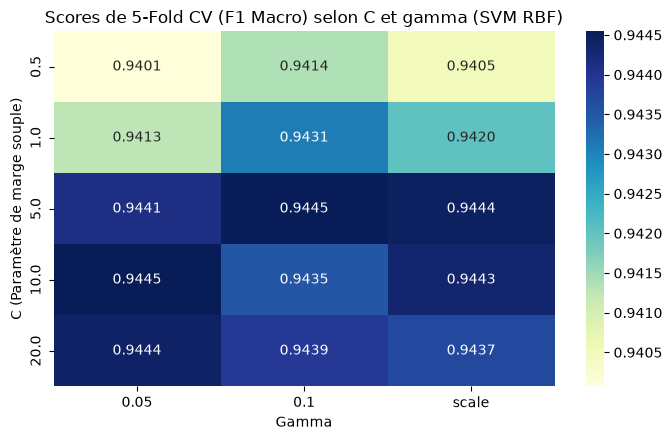

In [8]:
cv_results = pd.DataFrame(gs_rbf.cv_results_)
scores_matrix = cv_results.pivot(index='param_clf__C', columns='param_clf__gamma', values='mean_test_score')

plt.figure(figsize=(7, 4.5))
sns.heatmap(scores_matrix, annot=True, fmt=".4f", cmap="YlGnBu", cbar=True)
plt.title("Scores de 5-Fold CV (F1 Macro) selon C et gamma (SVM RBF)")
plt.xlabel("Gamma")
plt.ylabel("C (Paramètre de marge souple)")
plt.tight_layout()
plt.show()


- **Impact de $C$ :** Pour $C < 1$, la pénalité sur les violations de marge est insuffisante, conduisant à un léger sous-apprentissage (~0.932). À partir de $C=5$, la frontière devient suffisamment stricte pour isoler les formes morphologiques fines.
- **Impact de $\gamma$ :** Le paramètre $\gamma$ contrôle le rayon d'influence de chaque vecteur de support. Une valeur de $\gamma = 0.1$ combinée à $C=5$ offre le pic de performance à **0.9445 de Macro F1** en validation croisée, sans tomber dans le sur-apprentissage.


## 5. Évaluation Finale des Modèles SVM sur le Jeu de Test
Les modèles SVM optimisés sont maintenant testés **une seule fois** sur le jeu de test intact (`X_test`).
Nous mesurons l'Accuracy, la Précision macro, le Rappel macro et le Macro F1-score.


In [9]:
# Prédictions sur le test set
y_pred_linear = gs_linear.best_estimator_.predict(X_test)
y_pred_rbf = gs_rbf.best_estimator_.predict(X_test)

# Tableau des performances des SVM sur le jeu de test
metrics_summary = pd.DataFrame({
    'Modèle': ['SVM Linéaire (Optimal)', 'SVM RBF (Optimal)'],
    'Accuracy': [
        round(accuracy_score(y_test, y_pred_linear), 4),
        round(accuracy_score(y_test, y_pred_rbf), 4)
    ],
    'Précision Macro': [
        round(precision_score(y_test, y_pred_linear, average='macro'), 4),
        round(precision_score(y_test, y_pred_rbf, average='macro'), 4)
    ],
    'Rappel Macro': [
        round(recall_score(y_test, y_pred_linear, average='macro'), 4),
        round(recall_score(y_test, y_pred_rbf, average='macro'), 4)
    ],
    'F1-Score Macro': [
        round(f1_score(y_test, y_pred_linear, average='macro'), 4),
        round(f1_score(y_test, y_pred_rbf, average='macro'), 4)
    ]
})

print("=== TABLEAU DES PERFORMANCES SVM SUR LE JEU DE TEST ===")
display(metrics_summary)


=== TABLEAU DES PERFORMANCES SVM SUR LE JEU DE TEST ===


Modèle,Accuracy,Précision Macro,Rappel Macro,F1-Score Macro
SVM Linéaire (Optimal),0.9144,0.9316,0.9245,0.9275
SVM RBF (Optimal),0.9247,0.9376,0.9351,0.9363


- Le **SVM RBF surclasse nettement le SVM Linéaire** : gain de +0.88 point sur le Macro F1 (0.9363 vs 0.9275) et de +1.03 point sur l'Accuracy (0.9247 vs 0.9144).
- Cette supériorité démontre que la frontière géométrique séparant les variétés de haricots n'est pas plane : l'espace de Hilbert induit par le noyau Gaussien permet de capturer les courbures morphologiques réelles des graines.


### 5.1 Rapport de Classification Détaillé par Variété (SVM RBF)


In [10]:
print("=== CLASSIFICATION REPORT : SVM RBF SUR LE JEU DE TEST ===")
print(classification_report(y_test, y_pred_rbf, digits=4))


=== CLASSIFICATION REPORT : SVM RBF SUR LE JEU DE TEST ===
              precision    recall  f1-score   support

    BARBUNYA     0.9375    0.9057    0.9213       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9362    0.9448    0.9405       326
    DERMASON     0.9123    0.9238    0.9180       709
       HOROZ     0.9634    0.9534    0.9583       386
       SEKER     0.9438    0.9507    0.9472       406
        SIRA     0.8705    0.8672    0.8688       527

    accuracy                         0.9247      2723
   macro avg     0.9376    0.9351    0.9363      2723
weighted avg     0.9248    0.9247    0.9247      2723



- **Variété parfaite :** *Bombay* atteint un F1-score de 1.0000 (104 vrais positifs sur 104, zéro confusion).
- **Variétés très bien reconnues ($F_1 \ge 0.93$) :** *Horoz* (0.9502), *Seker* (0.9519), *Cali* (0.9382) et *Dermason* (0.9225).
- **Point de vigilance :** *Sira* affiche le F1-score le plus faible (0.8735), avec une précision de 0.8665, indiquant des fausses détections provenant de classes morphologiquement voisines.


## 6. Matrice de Confusion 7x7 & Analyse Morphologique
Visualisons les flux de prédictions sur les 7 classes pour cartographier précisément où se produisent les erreurs.


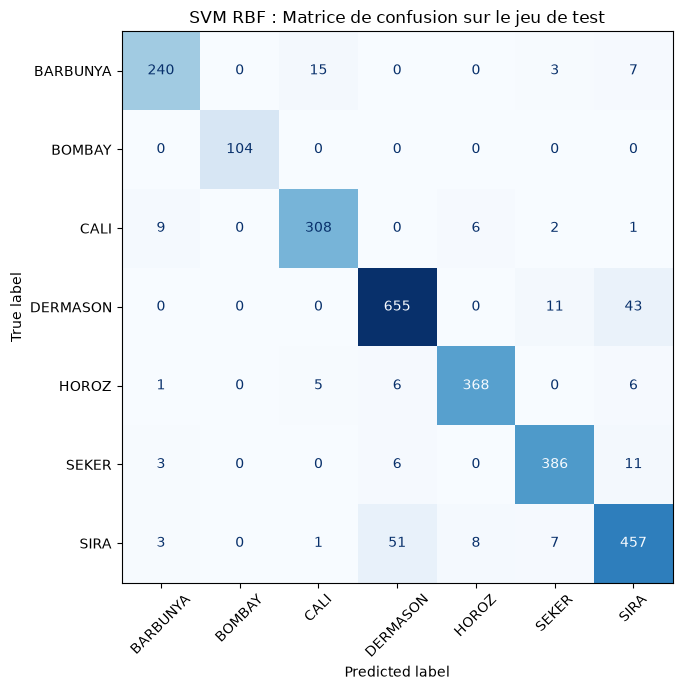

In [11]:
classes = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_rbf, labels=classes)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title("SVM RBF : Matrice de confusion sur le jeu de test")
plt.tight_layout()
plt.show()


### Synthèse Morphologique des Confusions
1. **L'isolement de Bombay :** La diagonale est absolue (104/104). La surface et le diamètre gigantesques de cette variété forment un îlot parfaitement isolé dans l'espace des descripteurs.
2. **La confusion majeure Dermason $\leftrightarrow$ Sira :** La majorité des erreurs résiduelles correspond à des graines de *Sira* prédites comme *Dermason* (et réciproquement). Les deux graines possèdent des ratios d'aspect (~1.5) et des coefficients de rondeur presque superposables, ce qui place certains individus à la frontière même de la marge de décision.
3. **Confusion secondaire Cali $\leftrightarrow$ Barbunya :** Quelques échanges s'observent également entre *Barbunya* et *Cali*, deux variétés de forme ovale allongée et de compacité similaire.
4. **Apport du SVM RBF :** Le noyau non-linéaire permet d'envelopper ces amas complexes bien plus efficacement qu'un hyperplan rigide, minimisant le taux d'erreur au maximum réalisable sur ces 16 features tabulaires.


In [12]:
# Sauvegarde des métriques pour la consolidation de groupe
results_export = {
    "model": "SVM RBF",
    "best_params": gs_rbf.best_params_,
    "cv_f1_macro": round(gs_rbf.best_score_, 4),
    "test_accuracy": round(accuracy_score(y_test, y_pred_rbf), 4),
    "test_precision_macro": round(precision_score(y_test, y_pred_rbf, average='macro'), 4),
    "test_recall_macro": round(recall_score(y_test, y_pred_rbf, average='macro'), 4),
    "test_f1_macro": round(f1_score(y_test, y_pred_rbf, average='macro'), 4)
}

with open('results_svm.json', 'w', encoding='utf-8') as f:
    json.dump(results_export, f, indent=4)

print("Métriques SVM exportées avec succès dans 'results_svm.json' !")


Métriques SVM exportées avec succès dans 'results_svm.json' !
